# Four particle sets

Run all cells to display the four sets of initial positions over the reflected, gyroaveraged potential.
The original particle IDs, positions and colors come from `data/particles/`.

- **40 particles:** the original star distribution.
- **84 particles:** the 40 original particles, eight additional probes and 36 neighbors.
- **8 chaotic candidates:** IDs 12, 15, 18, 21, 24, 27, 30 and 33.
- **8 periodic candidates:** IDs 1, 2, 60, 64, 65, 72, 76 and 83.

The last two names describe candidate selections, not verified dynamical classifications.
Circles mark original particles and probes; diamonds mark neighbors.
Change `phase` or enable `show_ids` below, then run again.
The radius comes from the thesis reference registry (currently `rho = 0.015`, in base-cell widths).
This notebook only displays the four panels; it does not integrate trajectories or export figures.


In [1]:
phase = 0.0       # Fraction of one forcing cycle, from 0 to 1.
show_ids = False  # Label particles with their original IDs.


In [2]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np

# Locate the code repository from this folder or either sibling repository.
candidates = (p for base in (Path.cwd(), *Path.cwd().parents)
              for p in (base, base / "GC2D_codigo"))
root = next((p for p in candidates
             if (p / "src/potential/potential.py").is_file()), None)
if root is None:
    raise FileNotFoundError("Open this notebook inside GC2D_codigo or its sibling TFM_redaccion.")
if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))

from dynamics.gc import GuidingCenterDynamics
from studies.main_campaign import SOURCE_SHA256, load_field

reference = json.loads((root.parent / "TFM_redaccion/datos/campana_referencia.json").read_text())
if reference["rho_convention"] != "base_cell_width" or reference["source_sha256"] != SOURCE_SHA256:
    raise ValueError("The reference radius convention or measured potential differs.")
rho = reference["representative_rho"]

files = ["original_40.json", "expanded_84.json",
         "chaotic_candidates.json", "periodic_candidates_8.json"]
datasets = [json.loads((root / "data/particles" / name).read_text()) for name in files]
for dataset, count in zip(datasets, (40, 84, 8, 8)):
    assert dataset["source_sha256"] == SOURCE_SHA256
    assert len(dataset["particles"]) == dataset["particle_count"] == count

field = load_field(root / "data/potential/V1/PHI_2.h5")
metadata = field.metadata
dynamics = GuidingCenterDynamics(field, rho=rho, B=1.5)
hamiltonian = dynamics.hamiltonian_potential
period = 1 / float(field.frequencies[0])
origin_m = np.array([metadata.source_x[0], metadata.source_y[0]])
if not 0 <= phase <= 1:
    raise ValueError("Choose a phase between 0 and 1.")


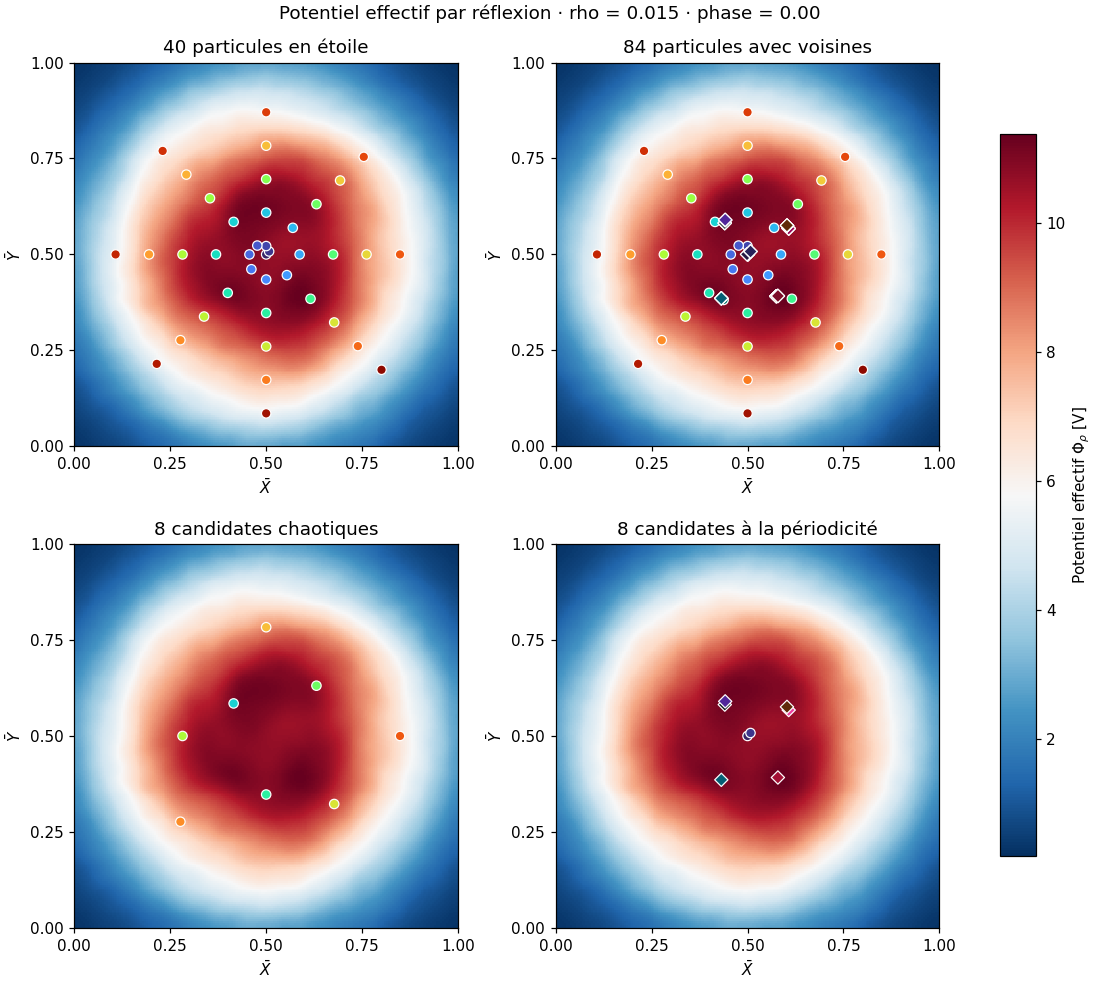

In [3]:
axis = np.linspace(0, 1, 201)
x, y = np.meshgrid(axis, axis)

# H = T * Phi_rho / (B * L**2); recover the effective potential in volts.
voltage_scale = dynamics.B * metadata.spatial_scale**2 / metadata.time_scale

def potential_at(cycle_phase):
    return voltage_scale * hamiltonian.evaluate(cycle_phase * period, x, y)

potential = potential_at(phase)
# Fixed color limits over the complete cycle (one temporal Fourier mode).
p0, p25, p50 = (potential_at(p) for p in (0, 0.25, 0.5))
mean = (p0 + p50) / 2
amplitude = np.hypot((p0 - p50) / 2, p25 - mean)
vmin, vmax = float(np.min(mean - amplitude)), float(np.max(mean + amplitude))
np.testing.assert_allclose(potential_at(1), p0, rtol=1e-11, atol=1e-12)

# Figure text follows the thesis convention: French in both editions.
figure_titles = {
    "original_40": "40 particules en étoile",
    "expanded_84": "84 particules avec voisines",
    "chaotic_candidates": "8 candidates chaotiques",
    "periodic_candidates_8": "8 candidates à la périodicité",
}

fig, axes = plt.subplots(2, 2, figsize=(10, 9), layout="constrained")
for ax, dataset in zip(axes.flat, datasets):
    particles = dataset["particles"]
    ids = np.array([p["id"] for p in particles])
    positions_m = np.array([p["position_m"] for p in particles]).reshape(-1, 2)
    xy = (positions_m - origin_m) / metadata.spatial_scale
    colors = np.array([p["color"] for p in particles])
    neighbors = np.array([p.get("kind") == "neighbor" for p in particles], dtype=bool)
    # Historical cell widths differ by rounding; physical positions remain exact.
    fractions = np.array([p["cell_fraction"] for p in particles]).reshape(-1, 2)
    np.testing.assert_allclose(xy, fractions, rtol=0, atol=1e-12)
    background = ax.pcolormesh(x, y, potential, shading="auto", cmap="RdBu_r",
                              vmin=vmin, vmax=vmax, rasterized=True)
    for mask, marker in ((~neighbors, "o"), (neighbors, "D")):
        ax.scatter(*xy[mask].T, c=colors[mask], s=38, marker=marker,
                   edgecolors="white", linewidths=0.8, zorder=3)
    if show_ids:
        for pid, point in zip(ids, xy):
            ax.annotate(str(pid), point, xytext=(4, 4), textcoords="offset points",
                        fontsize=7, bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=1))
    title = figure_titles[dataset["dataset_id"]]
    ax.set(title=title, xlabel=r"$\bar X$", ylabel=r"$\bar Y$",
           xlim=(0, 1), ylim=(0, 1), aspect="equal")
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1])

fig.suptitle(f"Potentiel effectif par réflexion · rho = {rho:g} · phase = {phase:.2f}")
fig.colorbar(background, ax=axes, shrink=0.8, label=r"Potentiel effectif $\Phi_\rho$ [V]")
plt.show()
